In [1]:
from datos import obtener_tickers

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
import yfinance as yf

In [2]:
# Descarga de datos diarios.

data_1d = obtener_tickers("1d" , "4y")

Se han cargado 273 tickers...
Tiempo de descarga en 32.45 segundos.
Se descargó datos en temporalidad 1d con un periodo de 4y


In [3]:
resultados_despegue_1d = []

for ticker in data_1d.columns.get_level_values(0).unique():
    if ticker in data_1d:
        df_ticker = data_1d[ticker].dropna(subset=['Close', 'High', 'Low'])
        df_ticker = df_ticker.iloc[:-1]
        
        if len(df_ticker) >= 400:
            cierre = df_ticker['Close']
            
            s_ema_21 = cierre.ewm(span=21, adjust=False).mean()
            s_ema_150 = cierre.ewm(span=150, adjust=False).mean()
            s_ema_200 = cierre.ewm(span=200, adjust=False).mean()
            
            delta = cierre.diff()
            gain = delta.clip(lower=0)
            loss = -1 * delta.clip(upper=0)
            avg_gain = gain.ewm(alpha=1/14, adjust=False).mean()
            avg_loss = loss.ewm(alpha=1/14, adjust=False).mean()
            rs = avg_gain / avg_loss
            s_rsi = 100 - (100 / (1 + rs))
            
            precio = cierre.iloc[-1].item()
            ema_21 = s_ema_21.iloc[-1].item()
            ema_150 = s_ema_150.iloc[-1].item()
            ema_200 = s_ema_200.iloc[-1].item()
            rsi_val = s_rsi.iloc[-1].item()

            pendiente_150 = ema_150 > s_ema_150.iloc[-20].item()
            pendiente_200 = ema_200 > s_ema_200.iloc[-20].item()
            estructura_valida = (ema_150 > ema_200) and pendiente_150 and pendiente_200

            dist_21 = ((precio - ema_21) / ema_21) * 100
            
            # Validación de cruce de cierre sobre la EMA 21 en las últimas 2 velas
            cruce_reciente = ((cierre > s_ema_21) & (cierre.shift(1) <= s_ema_21.shift(1))).iloc[-2:].any()
            arranque_temprano = (0.5 <= dist_21 <= 2.2) and cruce_reciente

            if estructura_valida and arranque_temprano:
                resultados_despegue_1d.append({
                    'ticker': ticker,
                    'precio': precio,
                    'ema_21': ema_21,
                    'dist_21': dist_21,
                    'rsi': rsi_val,
                    'df_plot': df_ticker.iloc[-252:].copy(),
                    'ema_21_plot': s_ema_21.iloc[-252:].copy(),
                    'ema_150_plot': s_ema_150.iloc[-252:].copy(),
                    'ema_200_plot': s_ema_200.iloc[-252:].copy(),
                    'rsi_plot': s_rsi.iloc[-252:].copy()
                })


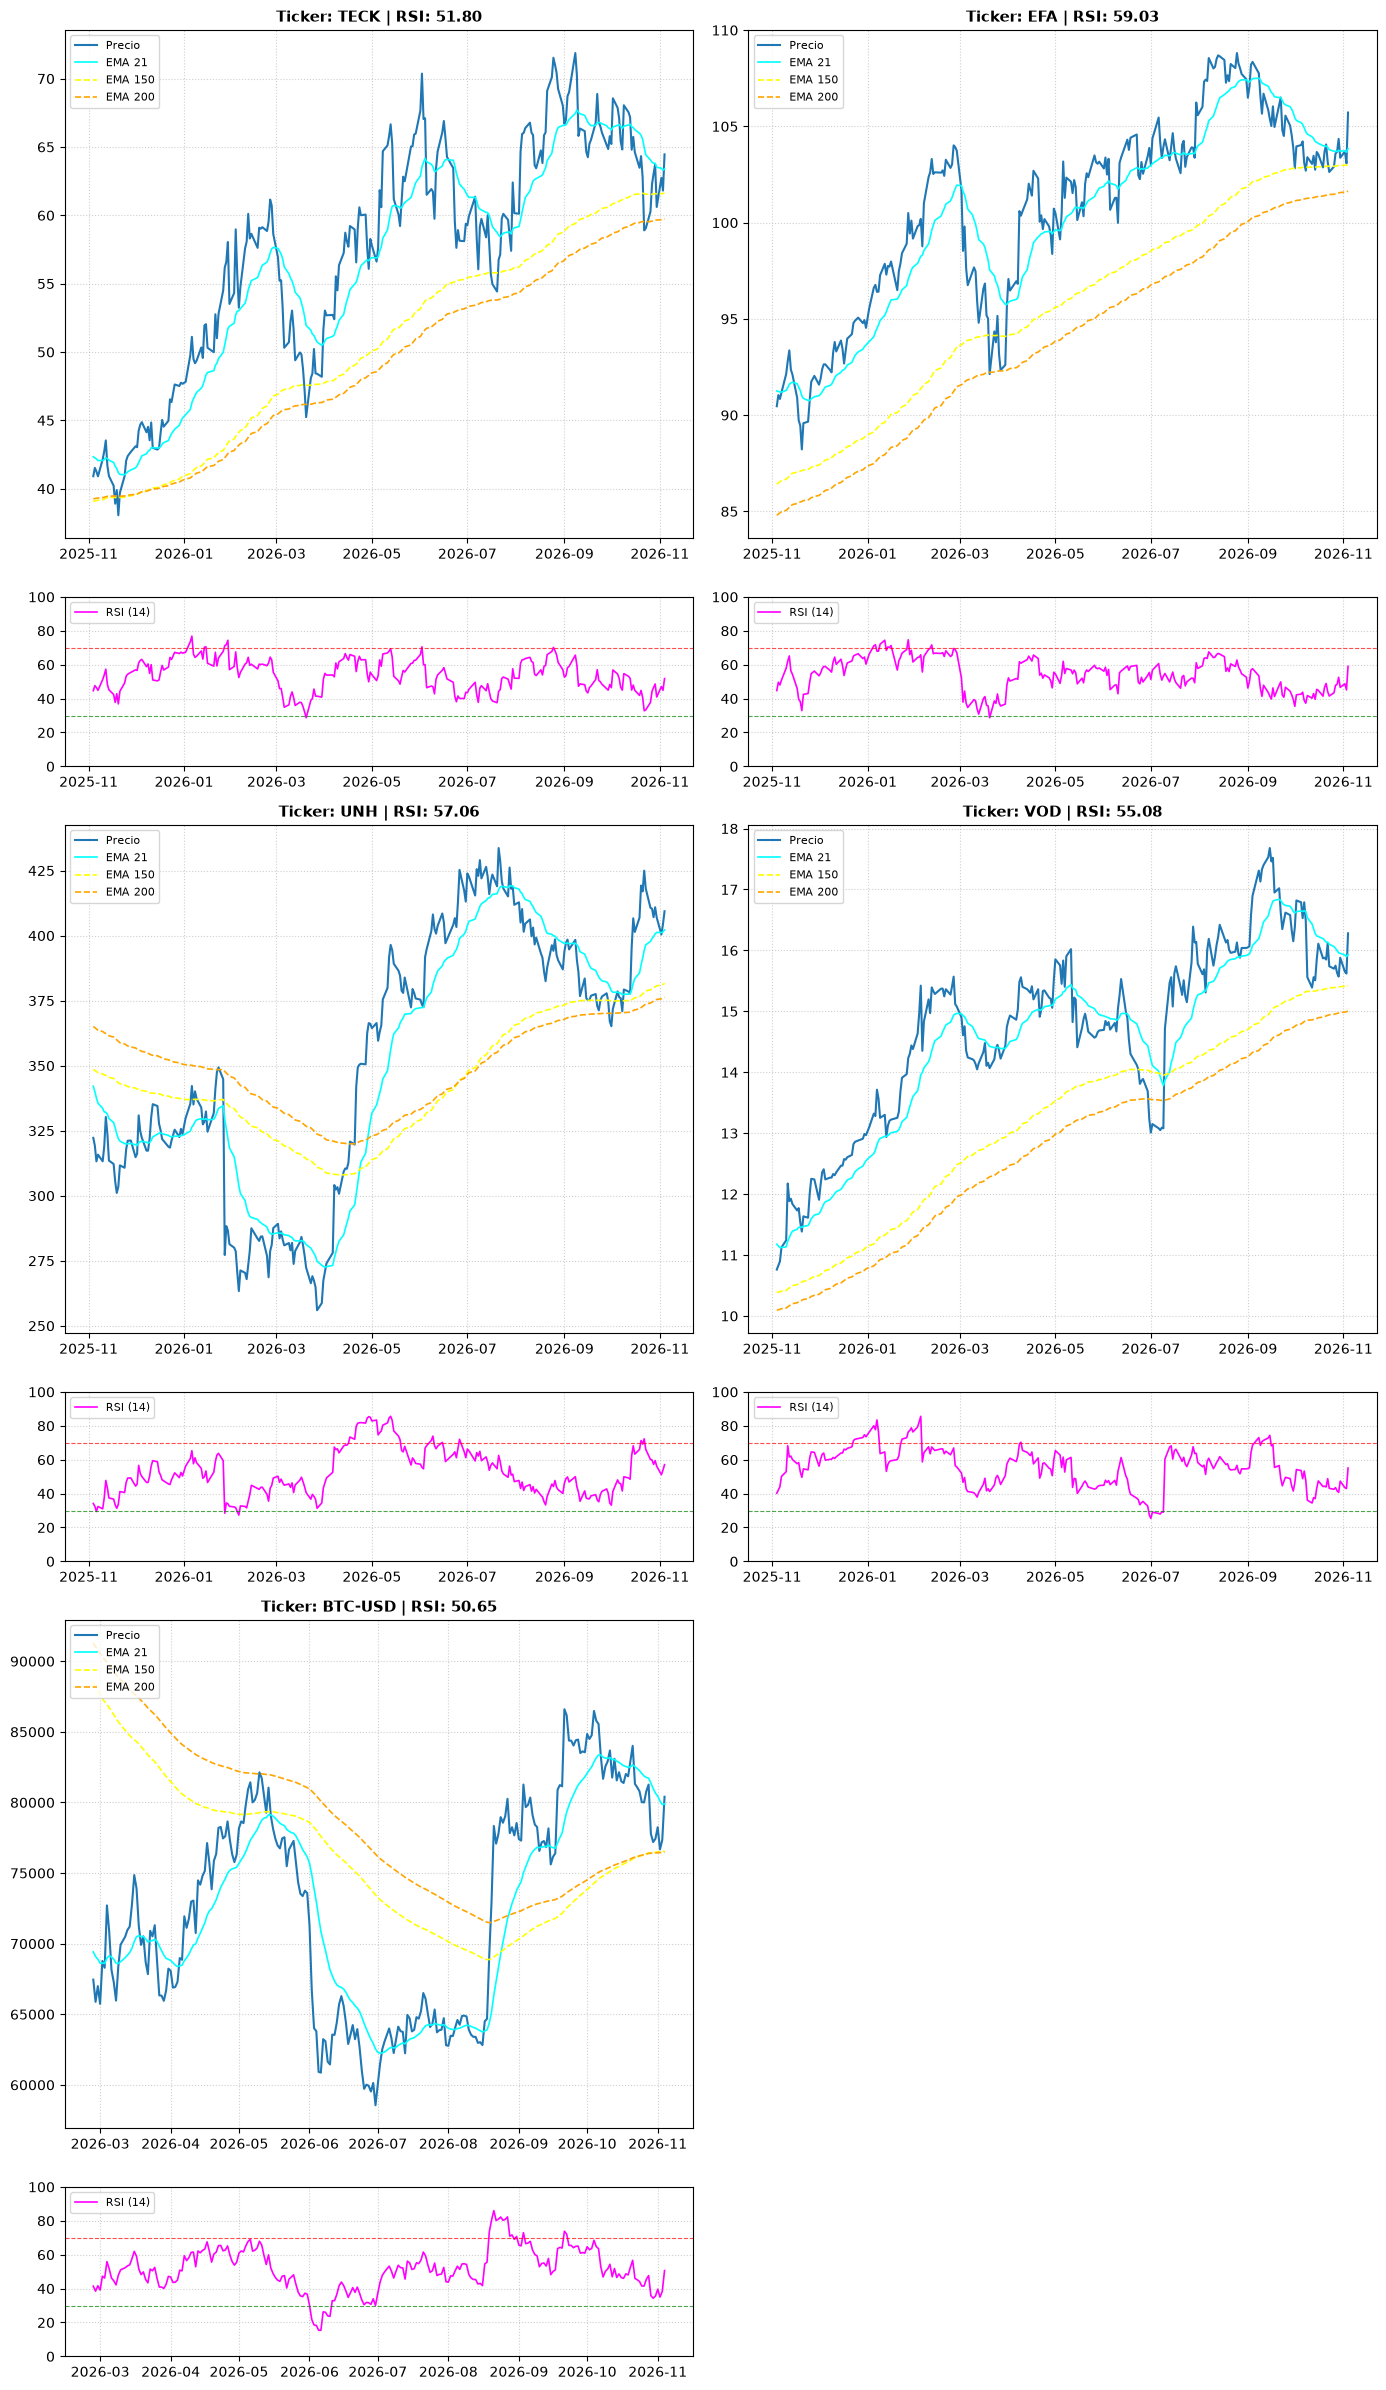

In [4]:
n_activos = len(resultados_despegue_1d)
if n_activos > 0:
    cols = 2 if n_activos > 1 else 1
    rows_per_activo = 2  # Precio + RSI por activo
    total_rows = math.ceil(n_activos / cols) * rows_per_activo
    
    fig = plt.figure(figsize=(14, 4 * total_rows))
    gs = fig.add_gridspec(total_rows, cols, height_ratios=[3, 1] * (total_rows // 2))
    
    for i, r in enumerate(resultados_despegue_1d):
        c_idx = i % cols
        r_base = (i // cols) * 2
        
        ax_price = fig.add_subplot(gs[r_base, c_idx])
        ax_rsi = fig.add_subplot(gs[r_base + 1, c_idx], sharex=ax_price)
        
        df_p = r['df_plot']
        
        ax_price.plot(df_p.index, df_p['Close'], label='Precio', color='#1f77b4', linewidth=1.5)
        ax_price.plot(df_p.index, r['ema_21_plot'], label='EMA 21', color='cyan', linestyle='-', linewidth=1.2)
        ax_price.plot(df_p.index, r['ema_150_plot'], label='EMA 150', color='yellow', linestyle='--', linewidth=1.2)
        ax_price.plot(df_p.index, r['ema_200_plot'], label='EMA 200', color='orange', linestyle='--', linewidth=1.2)
        ax_price.set_title(f"Ticker: {r['ticker']} | RSI: {r['rsi']:.2f}", fontsize=11, fontweight='bold')
        ax_price.grid(True, linestyle=':', alpha=0.6)
        ax_price.legend(loc='upper left', fontsize=8)
        
        ax_rsi.plot(df_p.index, r['rsi_plot'], label='RSI (14)', color='magenta', linewidth=1.2)
        ax_rsi.axhline(70, color='red', linestyle='--', linewidth=0.8, alpha=0.7)
        ax_rsi.axhline(30, color='green', linestyle='--', linewidth=0.8, alpha=0.7)
        ax_rsi.set_ylim(0, 100)
        ax_rsi.grid(True, linestyle=':', alpha=0.6)
        ax_rsi.legend(loc='upper left', fontsize=8)

    plt.tight_layout()
    plt.show()
else:
    print("Sin activos válidos para graficar.")